# Next-Day AQI Forecasting: Exploratory Data Analysis

**Goal:** predict tomorrow's AQI category (`tomorrow_status`, six classes from *Good* to *Severe*) for 14 Indian cities, using what is known today: AQI, prominent pollutants, weather and calendar.

**Data:** `data/processed/aqi_weather_2015_2025.csv`, built by the scripts in `code/`. It joins CPCB daily AQI bulletins (Urban Emissions compilation) with Open-Meteo daily weather, May 2015 to December 2025, one row per city per day.

**Contents**
1. Setup and loading
2. Data overview and quality
3. Categorical features
4. Target: `tomorrow_status`
5. Missing values
6. Target distribution
7. Numeric feature distributions
8. Features vs target
9. Collinearity
10. Summary of decisions

Each analysis ends with a **Finding → Decision** note. Reusable helpers (target, imputation, split, box-plot statistics) live in `utility.py`.

## 1. Setup and loading

In [1]:
%load_ext autoreload
%autoreload 2

import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utility import (AQI_CATEGORIES, aqi_to_category, ffill_aqi,
                     split_train_val_test, class_box_stats, class_signal_summary,
                     add_trend_features)

pd.set_option('display.max_columns', 40)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'axes.axisbelow': True})
COLOR = '#2a6fb0'

In [2]:
DATA_PATH = '../data/processed/aqi_weather_2015_2025.csv'

df = pd.read_csv(DATA_PATH, parse_dates=['date'])
df = df.rename(columns={'aqi_value': 'aqi_today', 'air_quality_status': 'status_today'})
df = df.drop(columns=['split'])          # the split is rebuilt from `date` (split_train_val_test)
df = df.sort_values(['city', 'date']).reset_index(drop=True)
df.shape

(51072, 20)

`aqi_value` and `air_quality_status` are renamed to `aqi_today` and `status_today` to make the time direction explicit: these are **today's** values, used as inputs for **tomorrow's** prediction. The precomputed `split` column is dropped; the same time-based split is recreated from `date` before modelling.

## 2. Data overview and quality

In [3]:
df.head()

,city,date,number_of_monitoring_stations,prominent_pollutants,aqi_today,status_today,temp_mean,temp_max,temp_min,humidity_mean,dew_point_mean,precip_sum,pressure_mean,cloud_cover_mean,wind_speed_mean,wind_speed_max,wind_u_mean,wind_v_mean,wind_dir_mean,temp_range
0,Bengaluru,2015-05-02,0.0,"CO, PM2.5",132.0,Moderate,25.65,32.3,21.5,70.00,19.13,2.8,912.20,54.46,2.11,3.57,1.79,0.32,259.84,10.8
1,Bengaluru,2015-05-03,0.0,"CO, PM2.5",49.0,Good,24.92,31.1,21.3,75.17,19.67,6.7,911.58,76.17,1.20,2.45,0.84,0.10,263.27,9.8
2,Bengaluru,2015-05-04,0.0,CO,46.0,Good,25.06,30.8,20.4,72.46,19.23,1.8,911.61,60.04,1.29,1.99,0.21,0.15,234.16,10.4
3,Bengaluru,2015-05-05,0.0,CO,229.0,Poor,25.57,30.8,20.0,64.04,17.40,0.0,911.34,77.79,1.68,2.52,-1.29,0.77,120.68,10.8
4,Bengaluru,2015-05-06,0.0,O3,90.0,Satisfactory,25.22,30.1,21.2,67.29,18.34,3.8,910.76,85.75,1.17,2.01,-0.21,0.24,139.27,8.9


In [4]:
summary = pd.DataFrame({
    'dtype': df.dtypes,
    'missing': df.isnull().sum(),
    'missing_%': (df.isnull().mean() * 100).round(2),
    'unique': df.nunique(),
}).sort_values('missing', ascending=False)
summary

,dtype,missing,missing_%,unique
prominent_pollutants,str,2139,4.19,52
number_of_monitoring_stations,float64,2138,4.19,41
aqi_today,float64,2138,4.19,487
status_today,str,2138,4.19,6
city,str,0,0.00,14
pressure_mean,float64,0,0.00,6893
wind_dir_mean,float64,0,0.00,24805
wind_v_mean,float64,0,0.00,1089
wind_u_mean,float64,0,0.00,1382
wind_speed_max,float64,0,0.00,929


**Finding:** all weather columns are complete. The four bulletin columns (`aqi_today`, `status_today`, `number_of_monitoring_stations`, `prominent_pollutants`) are missing together on about 4.2% of days, the days with no CPCB bulletin.
**Decision:** handle these rows in section 5, after the target is built.

In [5]:
print('Duplicate (city, date) rows:', df.duplicated(['city', 'date']).sum())

coverage = (df.groupby('city')
              .agg(first_day=('date', 'min'), last_day=('date', 'max'), days=('date', 'size'),
                   missing_aqi_pct=('aqi_today', lambda s: s.isna().mean() * 100),
                   mean_aqi=('aqi_today', 'mean'))
              .round({'missing_aqi_pct': 1, 'mean_aqi': 1})
              .sort_values('mean_aqi', ascending=False))
coverage

Duplicate (city, date) rows: 0


,first_day,last_day,days,missing_aqi_pct,mean_aqi
city,,,,,
Delhi,2015-05-01,2025-12-31,3898,0.6,214.8
Ghaziabad,2017-05-03,2025-12-31,3165,0.5,212.3
Greater Noida,2018-05-26,2025-12-31,2777,0.5,206.5
Faridabad,2015-05-01,2025-12-31,3898,10.9,200.3
Noida,2017-05-04,2025-12-31,3164,0.9,200.0
Gurugram,2015-12-15,2025-12-31,3670,8.6,196.1
Patna,2015-09-18,2025-12-31,3758,11.7,181.8
Lucknow,2015-05-02,2025-12-31,3897,2.8,170.4
Kanpur,2015-05-01,2025-12-31,3898,4.9,154.1


**Finding:** there are no duplicate city-days, so `shift()` and rolling windows are safe. Coverage is uneven: Ghaziabad and Noida start in 2017 and Greater Noida in 2018, so the early years are dominated by the other cities. Average AQI ranges from about 75 (Bengaluru) to about 215 (Delhi). Missing days are concentrated in Patna (11.7%), Faridabad (10.9%) and Gurugram (8.6%); most other cities miss under 5%.
**Decision:** keep all cities; the city-level differences are examined in section 3.1, and the gaps in section 5.

### 2.1 Label check

The AQI category should follow from the AQI value through the CPCB ranges (0–50 Good, 51–100 Satisfactory, 101–200 Moderate, 201–300 Poor, 301–400 Very Poor, 401–500 Severe).

In [6]:
known = df.dropna(subset=['aqi_today'])
from_value = aqi_to_category(known['aqi_today']).astype(str).rename('category from aqi_today')
mismatch = known[from_value != known['status_today']]

print(f'Rows whose label disagrees with their AQI value: {len(mismatch)}')
print('By year:', mismatch['date'].dt.year.value_counts().sort_index().to_dict())
pd.crosstab(mismatch['status_today'], from_value[mismatch.index])

Rows whose label disagrees with their AQI value: 56
By year: {2015: 4, 2018: 51, 2023: 1}


category from aqi_today,Good,Moderate,Poor,Satisfactory,Very Poor
status_today,,,,,
Moderate,0,0,0,24,0
Poor,0,4,0,0,0
Satisfactory,20,1,0,0,0
Severe,0,0,0,0,1
Very Poor,0,0,6,0,0


**Finding:** 56 rows carry a label that does not match their AQI value, almost all in 2018 (for example *Moderate* with an AQI in the *Satisfactory* range).
**Decision:** never use the text label as the target. Build `tomorrow_status` from the AQI **value** with `aqi_to_category`, and recompute `status_today` the same way (`ffill_aqi` does this).

## 3. Categorical features

In [7]:
categorical = df.select_dtypes(include=['object', 'string']).columns.tolist()
df[categorical].nunique()

city                    14
prominent_pollutants    52
status_today             6
dtype: int64

- `status_today` becomes the basis of the target (section 4).
- `city` is nominal (no order).
- `prominent_pollutants` is a comma-separated, multi-label field.

### 3.1 City

In [8]:
city_mix = (pd.crosstab(df['city'], df['status_today'], normalize='index') * 100).reindex(columns=AQI_CATEGORIES)
city_mix.round(0).sort_values('Good')

status_today,Good,Satisfactory,Moderate,Poor,Very Poor,Severe
city,,,,,,
Delhi,0.0,17.0,32.0,27.0,19.0,4.0
Ghaziabad,2.0,17.0,32.0,25.0,18.0,6.0
Greater Noida,2.0,16.0,35.0,27.0,16.0,4.0
Noida,2.0,19.0,35.0,23.0,16.0,5.0
Faridabad,3.0,18.0,34.0,26.0,15.0,5.0
Gurugram,3.0,17.0,34.0,29.0,15.0,2.0
Patna,3.0,26.0,31.0,24.0,13.0,3.0
Lucknow,4.0,28.0,35.0,20.0,12.0,2.0
Kanpur,8.0,33.0,33.0,12.0,10.0,3.0


**Finding:** cities behave very differently. Delhi NCR cities spend about 45–50% of days at *Poor* or worse, while Bengaluru, Chennai and Hyderabad almost never do. Cities with similar climates also differ: Patna (about 40% *Poor* or worse) is much worse than Kolkata (about 17%). Weather alone does not explain this; `city` stands in for emissions and geography, which the dataset does not measure.
**Decision:** keep `city` and one-hot encode it (14 columns). Once lag features exist, compare validation scores with and without `city`, since recent AQI history may already capture the city baseline.

### 3.2 Prominent pollutants

In [9]:
pollutants = df['prominent_pollutants'].dropna().str.split(',').explode().str.strip()
print('Distinct strings:', df['prominent_pollutants'].nunique())
print('Pollutants listed per day:', df['prominent_pollutants'].dropna().str.count(',').add(1).value_counts().sort_index().to_dict())
pollutants.value_counts()

Distinct strings: 52
Pollutants listed per day: {1: 24874, 2: 18565, 3: 5493, 4: 1}


prominent_pollutants
PM2.5    32009
PM10     26971
O3        8366
CO        7684
NO2       2985
SO2        458
NH3         14
Name: count, dtype: int64

In [10]:
flags = df['prominent_pollutants'].str.get_dummies(sep=', ')
flags.columns = 'has_' + flags.columns.str.lower().str.replace('.', '', regex=False)

df = pd.concat([df, flags], axis=1)
df = df.drop(columns=['prominent_pollutants', 'has_nh3'])   # NH3: only 14 days, too rare to learn from

flag_cols = [c for c in df.columns if c.startswith('has_')]
df[flag_cols].sum()

has_co       7684
has_no2      2985
has_o3       8366
has_pm10    26971
has_pm25    32009
has_so2       458
dtype: int64

**Finding:** the 52 distinct strings are combinations of 7 pollutants, and about half of all days list two or three. One-hot encoding the raw strings would create many rare columns.
**Decision:** turn the field into one 0/1 flag per pollutant and drop `has_nh3` (14 days). On days with no bulletin, every flag is 0; `aqi_imputed` (section 5) tells the model those flags are unknown.

## 4. Target: `tomorrow_status`

The model predicts **tomorrow's** category from **today's** data, so each row needs tomorrow's category as its label. `groupby('city')['aqi_today'].shift(-1)` moves each city's AQI up by one row, so every day receives the next day's AQI. `aqi_to_category` then converts it into the CPCB category.

| Rule | Why |
|---|---|
| Shift **within each city** | Bengaluru's last day must not receive Chennai's first day as "tomorrow" |
| Build from the AQI **value** | Avoids the 56 wrong labels found in section 2.1 |
| Build it **before** filling gaps | A filled (copied) AQI must never become an answer the model learns from |
| Features look back (`shift(+n)`), the target looks forward (`shift(-1)`) | Any feature that looks forward leaks the answer |

The last day of each city has no tomorrow, so its target is empty and the row is dropped in section 5.

In [11]:
df['tomorrow_status'] = aqi_to_category(df.groupby('city')['aqi_today'].shift(-1))
df['tomorrow_status'].value_counts(sort=False)

tomorrow_status
Good             4043
Satisfactory    16027
Moderate        15161
Poor             7890
Very Poor        4618
Severe           1181
Name: count, dtype: int64

In [12]:
# Sanity check: each row's target is the next day's category (Delhi, autumn 2023)
df.loc[(df['city'] == 'Delhi') & df['date'].between('2023-10-31', '2023-11-04'),
       ['city', 'date', 'aqi_today', 'status_today', 'tomorrow_status']]

,city,date,aqi_today,status_today,tomorrow_status
10900,Delhi,2023-10-31,359.0,Very Poor,Very Poor
10901,Delhi,2023-11-01,364.0,Very Poor,Very Poor
10902,Delhi,2023-11-02,392.0,Very Poor,Severe
10903,Delhi,2023-11-03,468.0,Severe,Severe
10904,Delhi,2023-11-04,415.0,Severe,Severe


On 2 November, today is *Very Poor* (392) but tomorrow is *Severe* (468). A "tomorrow equals today" guess misses exactly this kind of jump, which is where the model can add value.

## 5. Missing values

About 4.2% of days have no bulletin. The options were compared by hiding 3,000 known AQI values and filling them back:

| Method | Mean error (AQI points) | Category correct |
|---|---|---|
| Fill with 0 | 154 | 8% |
| Global mean | 83 | 32% |
| City mean | 67 | 37% |
| City and month mean | 43 | 52% |
| **Forward fill (last known value, same city)** | **29** | **68%** |
| Linear interpolation | 22 | 74%, but it uses tomorrow's value: **leakage** |

Forward fill is the most accurate method that uses only the past. First, check how long the gaps are:

In [13]:
missing = df['aqi_today'].isna()
gap_id = (missing != missing.groupby(df['city']).shift()).cumsum()
gaps = missing.groupby([df['city'], gap_id]).agg(['all', 'size'])
gap_len = gaps.loc[gaps['all'], 'size']

print(f'Gaps: {len(gap_len)} | 1 day: {(gap_len == 1).sum()} | '
      f'3 days or shorter: {(gap_len <= 3).mean():.0%} | longest: {gap_len.max()} days')
gap_len.value_counts().sort_index().head(10)

Gaps: 903 | 1 day: 577 | 3 days or shorter: 90% | longest: 177 days


size
1     577
2     158
3      75
4      29
5      17
6      12
7       4
8       5
9       5
10      5
Name: count, dtype: int64

In [14]:
print('Missing aqi_today before:', df['aqi_today'].isna().sum())

df = ffill_aqi(df, limit=3)       # fill gaps of up to 3 days; adds aqi_imputed, recomputes status_today
print('Filled (gaps of 3 days or shorter):', df['aqi_imputed'].sum())
print('Still missing (longer gaps):', df['aqi_today'].isna().sum())

rows_before = len(df)
df = df.dropna(subset=['aqi_today', 'tomorrow_status'])               # rows need a real input AND a real answer
df = df.drop(columns=['number_of_monitoring_stations'])                # describes the network, not the air
df = df.reset_index(drop=True)
print(f'Rows: {rows_before:,} -> {len(df):,}')
print('Missing values left:', df.isnull().sum().sum())
df.shape

Missing aqi_today before: 2138
Filled (gaps of 3 days or shorter): 1397
Still missing (longer gaps): 741
Rows: 51,072 -> 48,827
Missing values left: 0


(48827, 26)

**Finding:** 90% of gaps are 3 days or shorter (577 of the 903 gaps last a single day); 1,397 values are filled, and the 741 days in longer gaps are dropped, together with rows that have no real next-day AQI. In total 2,245 rows (4.4%) are removed, leaving 48,827 rows with no missing values. The class balance hardly changes.
**Decision:**
- Inputs may be filled; the target never is.
- `aqi_imputed = 1` marks filled days so the model can trust those values less.
- `number_of_monitoring_stations` is dropped: it has no relationship with AQI (correlation ≈ 0) and is missing whenever a day is filled.

## 6. Target distribution

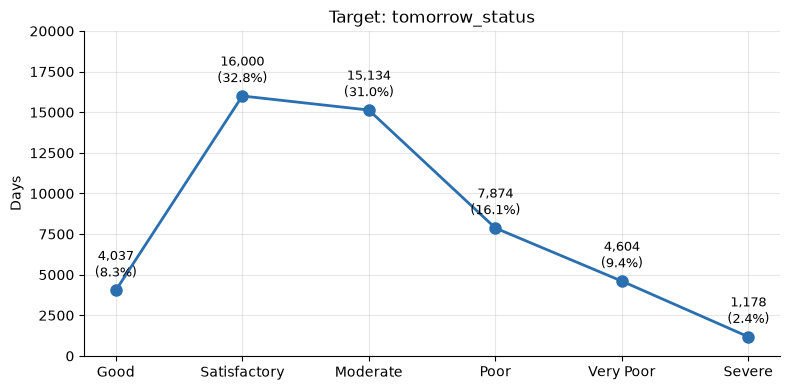

In [15]:
target = 'tomorrow_status'
counts = df[target].value_counts().reindex(AQI_CATEGORIES)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(counts.index, counts.values, color=COLOR, linewidth=2, marker='o', markersize=8)
for x, v in zip(counts.index, counts.values):
    ax.annotate(f'{v:,}\n({v / counts.sum():.1%})', (x, v), textcoords='offset points',
                xytext=(0, 10), ha='center', fontsize=9)
ax.set_title('Target: tomorrow_status')
ax.set_ylabel('Days')
ax.set_ylim(0, counts.max() * 1.25)
plt.tight_layout()
plt.show()

**Finding:** the classes are imbalanced. Satisfactory (32.8%) has about 13.6 times as many days as Severe (2.4%), and Satisfactory plus Moderate make up about two thirds of the data. A model could ignore Severe entirely and still reach a high accuracy.
**Decision:**
- Evaluate with **macro F1**, which gives every class equal weight, plus **recall on Very Poor and Severe**, the days that matter most.
- Train with `class_weight='balanced'` (weight = rows / (6 × rows in class)), which makes each Severe day count about 7 times more and each Satisfactory day about half.

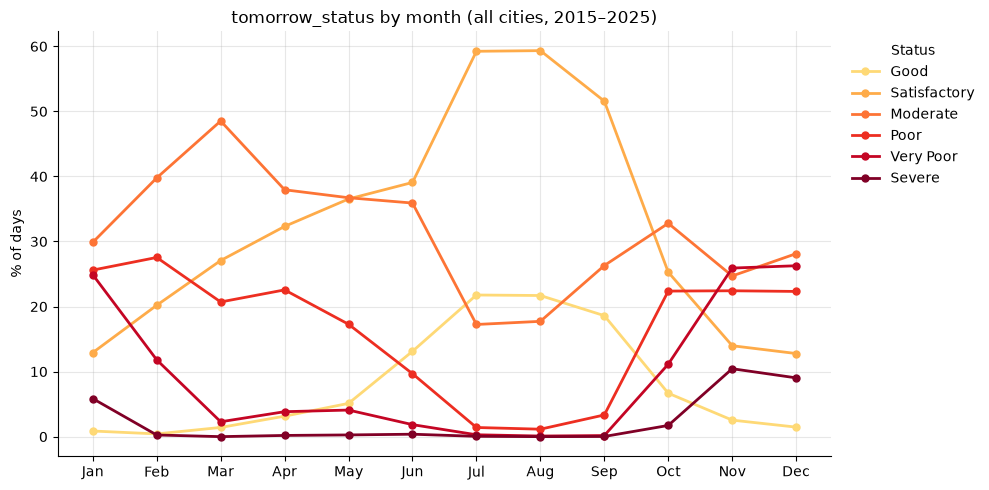

In [16]:
share = (pd.crosstab(df['date'].dt.month, df[target], normalize='index')
           .reindex(columns=AQI_CATEGORIES) * 100)
colors = plt.cm.YlOrRd(np.linspace(0.25, 1.0, len(AQI_CATEGORIES)))   # light = Good, dark = Severe

fig, ax = plt.subplots(figsize=(10, 5))
for cat, c in zip(AQI_CATEGORIES, colors):
    ax.plot(share.index, share[cat], color=c, linewidth=2, marker='o', markersize=5, label=cat)
ax.set_xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                             'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax.set_ylabel('% of days')
ax.set_title('tomorrow_status by month (all cities, 2015–2025)')
ax.legend(title='Status', bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)
plt.tight_layout()
plt.show()

**Finding:** strong seasonality. The monsoon (July–September) is mostly Satisfactory or Good, with almost no Poor days. Air quality worsens from October (stubble burning, cooler nights), and November to January is the worst period, with Severe peaking at about 10% of days in November. Severe days occur almost only in winter.
**Decision:** add `month` (and possibly a winter or stubble-season flag) as a feature. Expect Severe recall to be the hardest metric, because the model learns it from a few winter months.

## 7. Numeric feature distributions

A histogram shows one feature on its own: its shape, skew, unusual peaks and impossible values. Skew above about ±1 means a long tail, which can distort logistic regression.

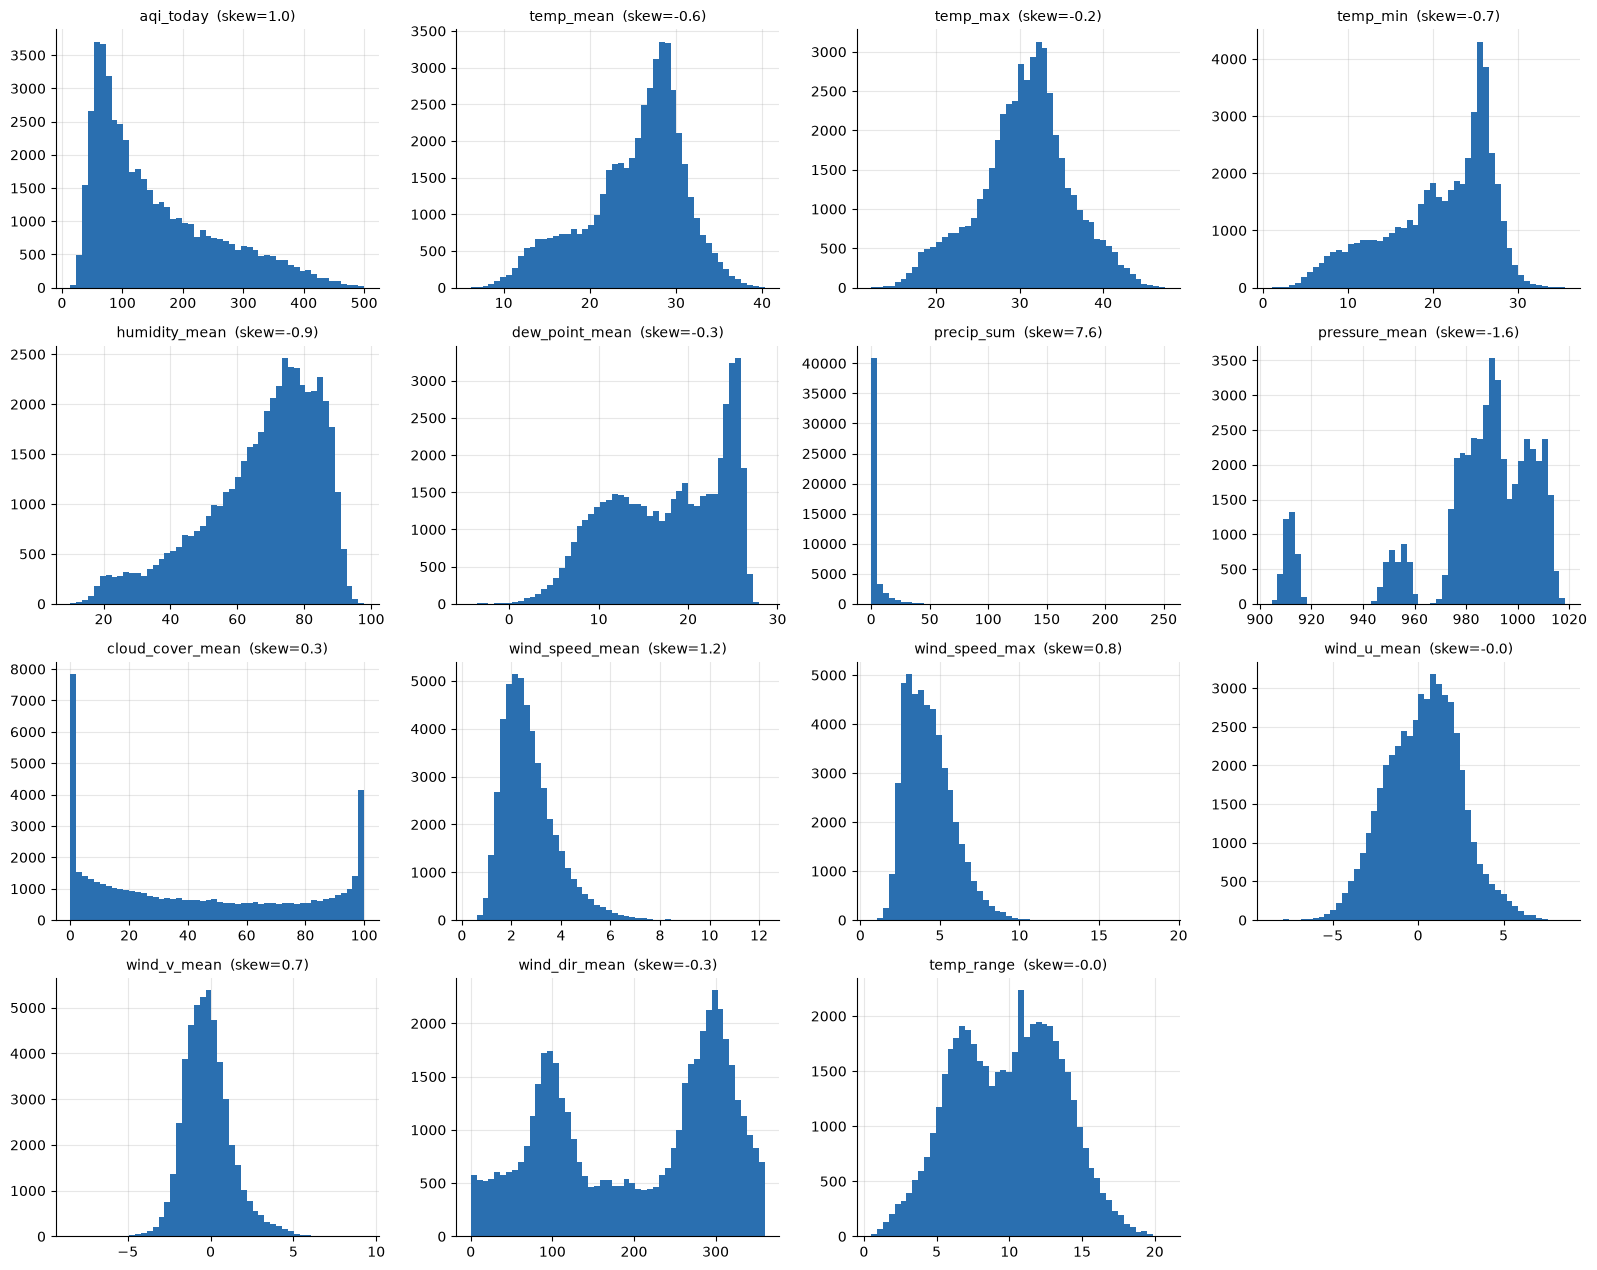

In [17]:
numerical = [c for c in df.select_dtypes(include='number').columns
             if not c.startswith('has_') and c != 'aqi_imputed']

ncols = 4
nrows = int(np.ceil(len(numerical) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.2 * nrows))
for ax, col in zip(axes.flat, numerical):
    ax.hist(df[col], bins=50, color=COLOR)
    ax.set_title(f'{col}  (skew={df[col].skew():.1f})', fontsize=10)
for ax in axes.flat[len(numerical):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

In [18]:
# Outliers by the IQR rule (outside Q1 - 1.5*IQR .. Q3 + 1.5*IQR), with the observed range
q1, q3 = df[numerical].quantile(0.25), df[numerical].quantile(0.75)
iqr = q3 - q1
outliers = ((df[numerical] < q1 - 1.5 * iqr) | (df[numerical] > q3 + 1.5 * iqr)).sum()

pd.DataFrame({'outliers': outliers,
              'pct': (outliers / len(df) * 100).round(1),
              'min': df[numerical].min(),
              'max': df[numerical].max()}).sort_values('outliers', ascending=False)

,outliers,pct,min,max
precip_sum,8427,17.3,0.00,251.10
pressure_mean,3849,7.9,904.52,1018.52
wind_speed_mean,1490,3.1,0.36,12.22
wind_v_mean,1444,3.0,-8.46,9.27
humidity_mean,986,2.0,10.08,97.92
temp_max,844,1.7,12.20,47.40
wind_speed_max,605,1.2,0.68,19.14
temp_mean,578,1.2,6.19,40.28
aqi_today,548,1.1,14.00,500.00
wind_u_mean,262,0.5,-8.57,8.61


In [19]:
# pressure_mean has three separate peaks: check whether they come from the cities
df.groupby('city')['pressure_mean'].median().sort_values().round(0)

city
Bengaluru         912.0
Hyderabad         953.0
Gurugram          982.0
Ghaziabad         983.0
Delhi             984.0
Faridabad         985.0
Noida             985.0
Greater Noida     986.0
Kanpur            992.0
Lucknow           994.0
Patna            1001.0
Kolkata          1006.0
Chennai          1007.0
Mumbai           1009.0
Name: pressure_mean, dtype: float64

**Findings:**
- `precip_sum` is very skewed (skew ≈ 7.6): about 0 on most days, up to 251 mm. Its 17% "outliers" are simply rainy days.
- `pressure_mean` has three peaks. This is **altitude**, not weather: the city medians are 912 hPa in Bengaluru and 953 hPa in Hyderabad, which sit higher, against 982–1009 hPa everywhere else. On its own, the feature mostly identifies the city.
- All values are physically plausible (humidity 10–98%, temperature 1–47 °C, AQI 14–500). The extremes are real events, including the Severe days the model most needs to learn.

**Decisions:**
- Remove no outliers.
- For logistic regression, use `np.log1p(precip_sum)` or a `rained` 0/1 flag. Tree models need no transformation.
- Replace `pressure_mean` with pressure relative to each city's normal (`pressure_mean` minus the city's **training-set** mean), or drop it. Decide on validation.

## 8. Features vs target

A box plot per class shows how today's value of a feature relates to **tomorrow's** category. The box holds the middle 50% of days and the line is the median. Four questions read the signal:

1. **Do the medians move in a clear direction?** Yes means the feature carries signal.
2. **Do the boxes overlap?** Heavy overlap means the feature alone cannot separate those classes.
3. **Is the pattern straight or does it bend?** Logistic regression can only follow straight-line patterns; trees can follow bends.
4. **Which classes look the same?** Those classes need other features to tell them apart.

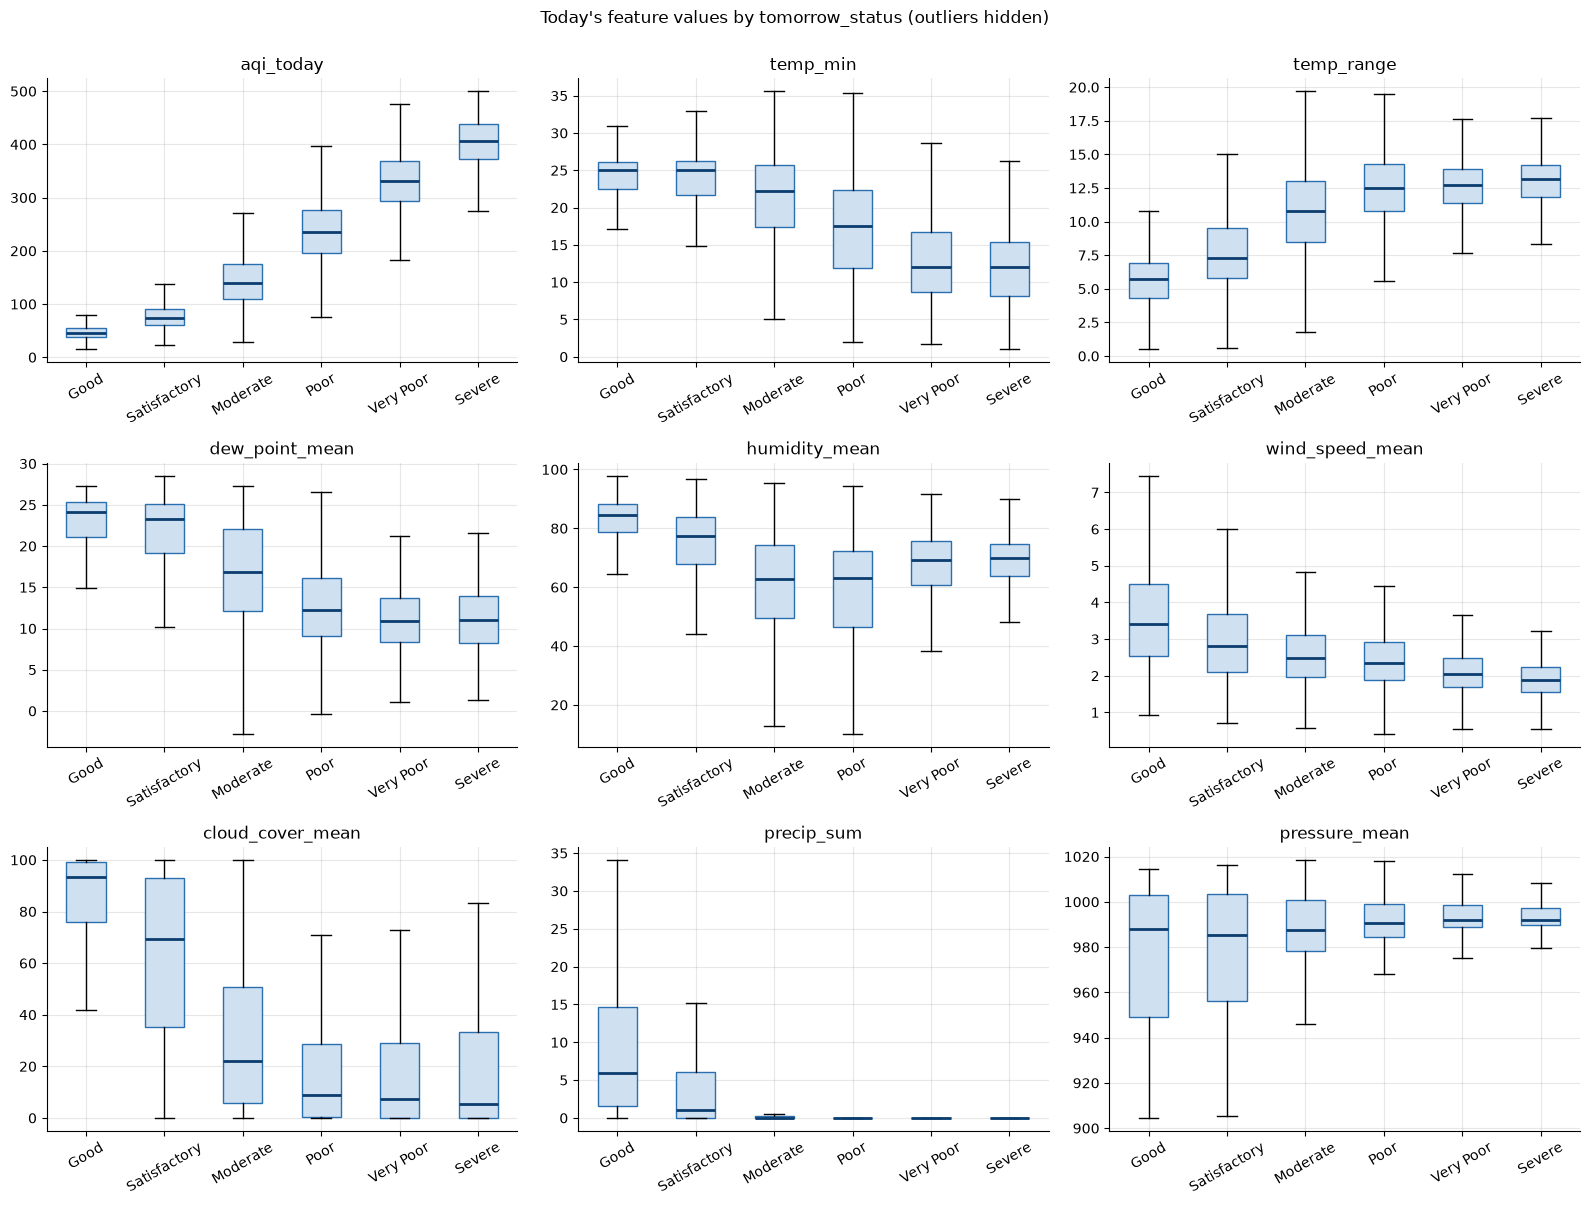

In [20]:
features = ['aqi_today', 'temp_min', 'temp_range', 'dew_point_mean', 'humidity_mean',
            'wind_speed_mean', 'cloud_cover_mean', 'precip_sum', 'pressure_mean']

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.flat, features):
    groups = [df.loc[df[target] == c, col] for c in AQI_CATEGORIES]
    ax.boxplot(groups, tick_labels=AQI_CATEGORIES, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor='#cfe0f1', color=COLOR),
               medianprops=dict(color='#0b3d6e', linewidth=2))
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=30)
plt.suptitle('Today\'s feature values by tomorrow_status (outliers hidden)', y=1.0)
plt.tight_layout()
plt.show()

`class_signal_summary` (in `utility.py`) turns the box plots into numbers, one row per feature. How to read each column:

| Column | Plain question | How to read it | Example |
|---|---|---|---|
| `rho` | Does the feature go up or down as tomorrow gets worse? | A score from −1 to +1. **Near 0** = no link. **Plus** = the value rises as air gets worse, **minus** = it falls. The further from 0, the stronger the link. | `aqi_today` 0.88 (strong); `temp_min` −0.51 (colder nights before worse air); `pressure_mean` 0.16 (weak) |
| `direction` | The same answer in words | `up` / `down` (strong, \|rho\| ≥ 0.3), `weak up` / `weak down` (0.1–0.3), `none` (below 0.1) | |
| `medians` | What is the typical value in each class? | The middle line of each box, from Good to Severe | `temp_min`: 25 → 25 → 22 → 17.5 → 12 → 12 |
| `avg_box_overlap` | Do neighbouring boxes sit on top of each other? | **0** = boxes apart, the feature tells the classes apart easily. **1** = one box fully inside the other, it cannot. Averaged over the five neighbouring pairs (Good–Satisfactory, Satisfactory–Moderate, …). | `aqi_today` 0.00; `temp_min` 0.80 |
| `good_vs_severe_overlap` | Can it at least tell the best days from the worst? | Same 0-to-1 scale, but only Good against Severe | `pressure_mean` 1.0: Good and Severe days have the same pressure |
| `linear_r2` | How close are the six medians to a straight line? | **1** = perfectly straight; lower = more curved | `aqi_today` 0.98 |
| `shape` | What does the line of medians look like? | **straight**: a steady rise or fall, any model can use it. **bends**: it moves, then flattens. **reverses**: it goes down and then up (a U-shape), which logistic regression cannot use. | `aqi_today` straight; `temp_min` bends; `humidity_mean` reverses (84 → 63 → 70) |
| `same_as` | Which neighbouring classes look the same? | Two classes are listed when their medians are almost equal **and** their boxes mostly overlap: this feature cannot tell them apart. | `temp_min`: Very Poor≈Severe (both 12 °C) |

**Reading a row as a sentence.** `temp_min`: *colder nights come before worse air (`rho` −0.51, `down`), but the boxes overlap a lot (0.80), so temperature cannot decide on its own. The drop flattens at the bad end (`bends`), and it cannot tell Very Poor from Severe (`same_as`).*

These are rules of thumb, not statistical tests. The cut-offs (for example 0.3 for a strong `rho`) can be changed in the function. `rho` is a Spearman correlation: it only uses the *order* of the values, which suits ordered classes like Good → Severe.

In [21]:
class_signal_summary(df, features)

,rho,direction,medians,avg_box_overlap,good_vs_severe_overlap,linear_r2,shape,same_as
feature,,,,,,,,
aqi_today,0.88,up,46 → 73 → 139 → 236 → 332 → 406,0.00,0.0,0.98,straight,-
temp_range,0.63,up,5.7 → 7.3 → 10.8 → 12.5 → 12.7 → 13.2,0.64,0.0,0.88,bends,Poor≈Very Poor
dew_point_mean,-0.63,down,24.2 → 23.3 → 16.8 → 12.3 → 10.9 → 11.1,0.77,0.0,0.89,bends,Very Poor≈Severe
precip_sum,-0.60,down,5.9 → 1.1 → 0 → 0 → 0 → 0,0.95,0.0,0.55,bends,"Moderate≈Poor, Poor≈Very Poor, Very Poor≈Severe"
cloud_cover_mean,-0.59,down,93.5 → 69.2 → 22 → 9 → 7.4 → 5.4,0.78,0.0,0.82,bends,"Poor≈Very Poor, Very Poor≈Severe"
temp_min,-0.51,down,25.1 → 25.1 → 22.2 → 17.5 → 12 → 12,0.80,0.0,0.93,bends,"Good≈Satisfactory, Very Poor≈Severe"
humidity_mean,-0.40,down,84.5 → 77.3 → 62.8 → 63 → 69.2 → 69.8,0.73,0.0,0.38,reverses,"Moderate≈Poor, Very Poor≈Severe"
wind_speed_mean,-0.32,down,3.4 → 2.8 → 2.5 → 2.4 → 2 → 1.9,0.82,0.0,0.94,bends,-
pressure_mean,0.16,weak up,987.9 → 985.3 → 987.5 → 990.4 → 992.2 → 991.9,1.00,1.0,0.73,reverses,Very Poor≈Severe


In [22]:
# The numbers behind the box plots, for checking by hand
class_box_stats(df, ['aqi_today', 'temp_min'])

tomorrow_status   Good  Satisfactory  Moderate    Poor  Very Poor  Severe
          stat                                                           
aqi_today q1      39.0          60.0     110.0  196.25      294.0  372.00
          median  46.0          73.0     139.0  236.00      332.0  406.00
          q3      55.0          91.0     175.0  277.00      368.0  438.00
temp_min  q1      22.5          21.7      17.4   11.90        8.7    8.10
          median  25.1          25.1      22.2   17.50       12.0   12.00
          q3      26.1          26.3      25.7   22.40       16.7   15.38

**Findings:**
- `aqi_today` is by far the strongest signal (rho = 0.88). It is the only feature whose boxes do not overlap at all, with a straight, steady rise.
- `temp_min`, `temp_range`, `dew_point_mean`, `cloud_cover_mean` and `precip_sum` are strong (|rho| about 0.5–0.6). Cold, dry, clear and calm days come before bad air, as the inversion physics predicts.
- The weather features **bend**: they change a lot between Good and Poor, then flatten. **Very Poor and Severe look the same in almost every weather feature.** Weather signals that a bad day is coming, but not how bad; only `aqi_today` separates them clearly.
- `humidity_mean` **reverses** (U-shape, lowest at Moderate and Poor), which logistic regression cannot use.
- `pressure_mean` shows almost no signal (rho = 0.16; the Severe box lies entirely inside the Good box), consistent with the altitude effect in section 7.

**Decisions:**
- Keep `aqi_today` and the strong weather features.
- Add lag and rolling features (section 10) so the model can see the recent trend, not only today.
- The bends and the U-shape suggest that tree models (random forest, XGBoost) will beat logistic regression; logistic regression remains the interpretable baseline.

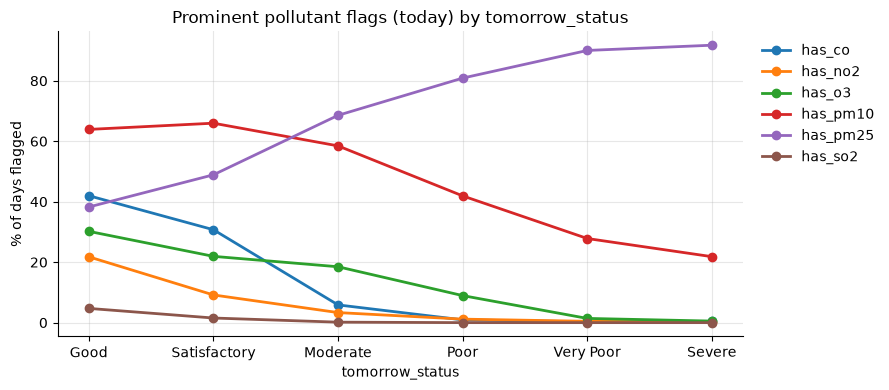

,has_co,has_no2,has_o3,has_pm10,has_pm25,has_so2
tomorrow_status,,,,,,
Good,42.0,21.8,30.2,63.9,38.2,4.7
Satisfactory,30.7,9.2,21.9,66.0,48.9,1.5
Moderate,5.9,3.3,18.5,58.5,68.6,0.2
Poor,0.9,1.2,8.9,41.9,80.9,0.0
Very Poor,0.3,0.4,1.4,27.8,90.0,0.0
Severe,0.4,0.2,0.5,21.8,91.8,0.0


In [23]:
flag_share = (df.groupby(target, observed=True)[flag_cols].mean() * 100).reindex(AQI_CATEGORIES)

fig, ax = plt.subplots(figsize=(9, 4))
flag_share.plot(ax=ax, marker='o', linewidth=2)
ax.set_ylabel('% of days flagged')
ax.set_title('Prominent pollutant flags (today) by tomorrow_status')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)
plt.tight_layout()
plt.show()
flag_share.round(1)

**Finding:** PM2.5 drives the bad days: it is prominent on about 92% of the days before a Severe day, against 38% before a Good day. CO, O<sub>3</sub> and NO<sub>2</sub> mostly appear before clean days: when particles are low, a gas becomes the "worst" pollutant even though the air is clean overall. PM10 is common on cleaner days (dust) and falls as AQI rises.
**Decision:** keep the six flags; they add information about *which* pollutant drives the AQI, which the AQI value alone does not show.

## 9. Collinearity

Collinear features carry the same information. This makes logistic regression coefficients unstable and hard to interpret; tree models are not affected. Two checks are used: the correlation matrix for pairs, and the VIF for each feature against **all** the others.

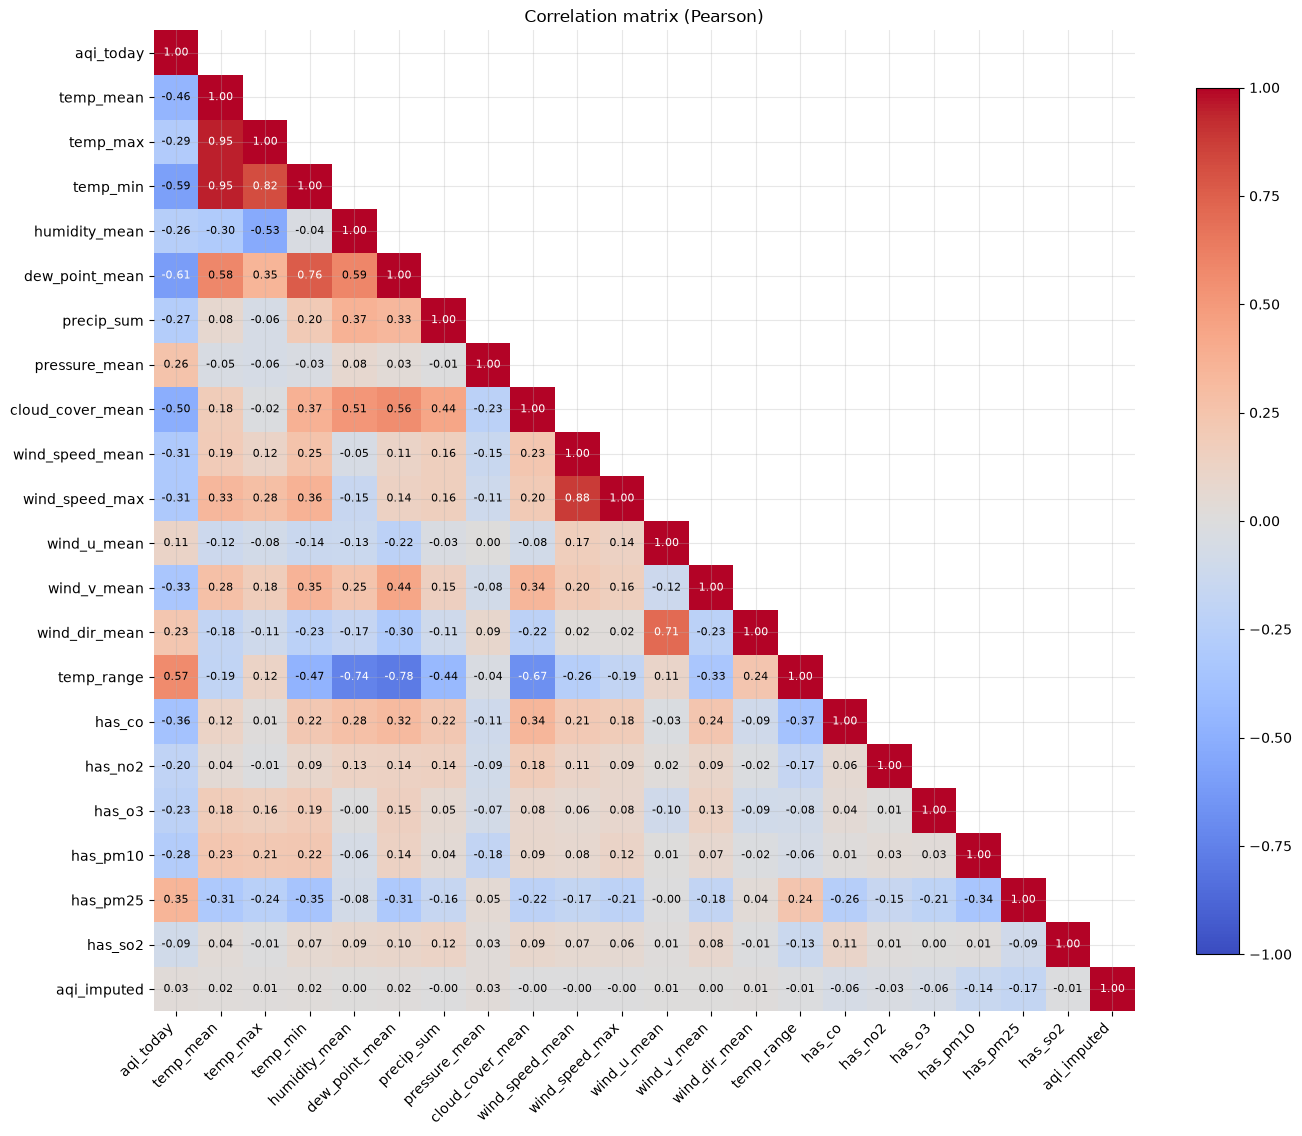

In [24]:
corr = df.corr(numeric_only=True)
n = len(corr)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)      # hide the mirrored upper triangle

fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(corr.mask(mask), cmap='coolwarm', vmin=-1, vmax=1)
for i in range(n):
    for j in range(i + 1):
        v = corr.iloc[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(v) > 0.6 else 'black')
ax.set_xticks(range(n), corr.columns, rotation=45, ha='right')
ax.set_yticks(range(n), corr.columns)
ax.spines[:].set_visible(False)
fig.colorbar(im, shrink=0.8)
ax.set_title('Correlation matrix (Pearson)')
plt.tight_layout()
plt.show()

In [25]:
# Feature pairs with |r| >= 0.6 (the aqi_today row shows relevance, not collinearity)
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
(upper.stack().rename('r').to_frame()
      .assign(abs_r=lambda d: d['r'].abs())
      .query('abs_r >= 0.6')
      .sort_values('abs_r', ascending=False))

r     abs_r
temp_mean        temp_min        0.952840  0.952840
                 temp_max        0.947986  0.947986
wind_speed_mean  wind_speed_max  0.880211  0.880211
temp_max         temp_min        0.816338  0.816338
dew_point_mean   temp_range     -0.777227  0.777227
temp_min         dew_point_mean  0.760958  0.760958
humidity_mean    temp_range     -0.740050  0.740050
wind_u_mean      wind_dir_mean   0.705834  0.705834
cloud_cover_mean temp_range     -0.672468  0.672468
aqi_today        dew_point_mean -0.605058  0.605058

A correlation matrix only compares two features at a time. `temp_range` is exactly `temp_max − temp_min`, a three-way dependency that no single cell shows. The VIF (variance inflation factor) catches it. VIF is computed on the **training years only**: 1–5 is fine, 5–10 is moderate, above 10 is serious.

In [26]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant


def vif_table(X):
    """VIF for each column of X. An intercept is added, as VIF requires.
    VIF needs complete rows, so rows with a missing or infinite value are skipped (and counted)."""
    complete = np.isfinite(X).all(axis=1)
    if not complete.all():
        print(f'VIF: skipped {(~complete).sum():,} rows with missing values. '
              'After section 5 there should be none: restart the kernel and run all cells.')
    Xc = add_constant(X[complete])
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')        # perfectly collinear sets warn about a singular matrix
        vif = [variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])]
    return pd.Series(vif, index=X.columns, name='VIF').sort_values(ascending=False).round(2)


df_train, df_val, df_test = split_train_val_test(df)

all_weather = ['aqi_today', 'temp_mean', 'temp_max', 'temp_min', 'temp_range', 'humidity_mean',
               'dew_point_mean', 'precip_sum', 'pressure_mean', 'cloud_cover_mean',
               'wind_speed_mean', 'wind_speed_max', 'wind_u_mean', 'wind_v_mean']
vif_table(df_train[all_weather]).to_frame('VIF: all weather features')

,VIF: all weather features
temp_max,1.000800e+15
temp_min,1.000800e+15
temp_range,1.000800e+15
temp_mean,2.282200e+02
dew_point_mean,4.571000e+01
humidity_mean,3.526000e+01
wind_speed_mean,5.550000e+00
wind_speed_max,5.460000e+00
cloud_cover_mean,2.410000e+00
aqi_today,2.330000e+00


In [27]:
lr_numerical = ['aqi_today', 'temp_min', 'temp_range', 'humidity_mean', 'precip_sum',
                'pressure_mean', 'cloud_cover_mean', 'wind_speed_mean',
                'wind_u_mean', 'wind_v_mean']
vif_table(df_train[lr_numerical]).to_frame('VIF: reduced set for logistic regression')

,VIF: reduced set for logistic regression
temp_range,7.38
humidity_mean,5.24
temp_min,3.25
cloud_cover_mean,2.36
aqi_today,2.33
wind_speed_mean,1.43
wind_v_mean,1.35
pressure_mean,1.33
precip_sum,1.31
wind_u_mean,1.09


**Findings:**
- **Temperature.** `temp_max`, `temp_min` and `temp_range` are perfectly collinear (VIF ≈ 10<sup>15</sup>), because `temp_range` is exactly `temp_max − temp_min`. `temp_mean` is a near-duplicate as well (r = 0.95 with both `temp_min` and `temp_max`; VIF ≈ 228).
- **Moisture.** `dew_point_mean` (VIF ≈ 46) and `humidity_mean` (VIF ≈ 35) are also above 10, which is serious. Both fall as `temp_range` rises (r = −0.78 and −0.74): on humid days the gap between day and night temperature is small. `dew_point_mean` also follows `temp_min` (r = 0.76). `humidity_mean` does not (r ≈ 0); it falls as `temp_max` rises (r = −0.53).
- **Wind.** `wind_speed_mean` and `wind_speed_max` correlate at 0.88, but their VIF is only moderate (≈ 5.5 each). `wind_dir_mean` correlates 0.71 with `wind_u_mean`; it is left out of the VIF lists because it is an angle (359° and 1° are neighbours, but far apart as numbers).
- **Clouds.** `cloud_cover_mean` and `temp_range` correlate at −0.67 (cloudy days have smaller day–night swings), but the VIF of `cloud_cover_mean` is low (≈ 2.4), so no action is needed.
- **Reduced set.** Every VIF is below 10. Only `temp_range` (≈ 7.4) and `humidity_mean` (≈ 5.2) are above 5. Removing `humidity_mean` as well brings `temp_range` down to ≈ 2.8.

**Decisions:**
- For **logistic regression**, drop `temp_mean`, `temp_max`, `wind_speed_max`, `dew_point_mean` and `wind_dir_mean` (`wind_u_mean` and `wind_v_mean` encode the same direction without the 359°→0° jump). Test dropping `humidity_mean` as well on validation: it removes the last moderate VIF, and logistic regression cannot use its U-shape anyway (section 8).
- For **tree models**, keep all features.
- Repeat this check after adding the lag and rolling features: `aqi_roll7_mean` correlates 0.92 with `aqi_today` (section 10).

## 10. Why lag and rolling features?

**The problem.** The model looks at one row at a time. Each row is one city on one day, and the model does not read the rows in order. From `aqi_today` alone it cannot tell whether AQI has been climbing all week or jumped only today. A person forecasting tomorrow would look at the last few days, not only at today.

**The fix.** Copy a short summary of the recent past into today's row. Each feature answers one simple question:

| Feature | Question it answers | Delhi, 2 Nov 2023 |
|---|---|---|
| `aqi_roll7_mean` | What has the usual level been this week? | 336 |
| `aqi_roll7_std` | Has the week been calm or jumpy? | 43.5 |
| `aqi_diff1` | Is AQI rising or falling since yesterday? | +28 |
| `aqi_dev7` | How unusual is today compared with the previous 7 days? | +75 |
| `month` | What time of year is it? (section 6) | 11 |

**Three rules keep the features honest** (`add_trend_features` in `utility.py`):
1. **Only the past.** Every feature uses today and earlier days, never tomorrow, which is the answer.
2. **Within each city.** Delhi's past never ends up in Bengaluru's row.
3. **By calendar day.** "Yesterday" is always the previous date. If that day is missing, the feature is left empty (NaN) instead of quietly using an older day.

### 10.1 Does AQI remember its past?

If today's AQI had nothing to do with last week's, the past would be useless to the model. **Autocorrelation** measures this: the correlation between a city's AQI today and its AQI *k* days earlier. How fast it fades also tells us how long the window should be.

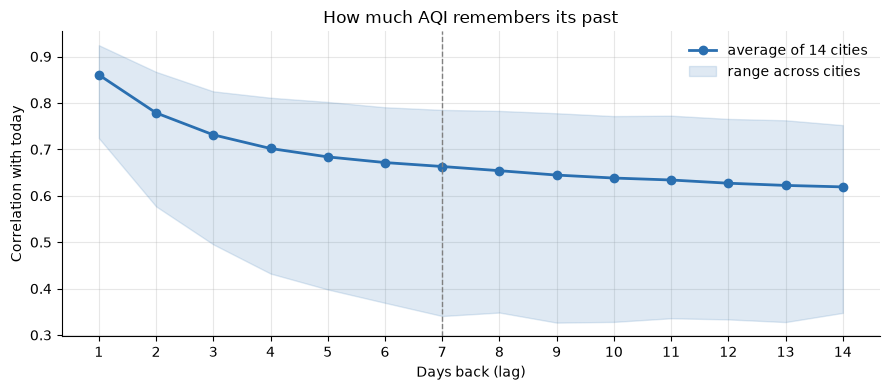

,1,2,3,4,5,6,7,8,9,10,11,12,13,14
avg correlation,0.86,0.78,0.73,0.7,0.68,0.67,0.66,0.65,0.64,0.64,0.63,0.63,0.62,0.62


In [69]:
# Autocorrelation: how similar is AQI to its value k days earlier? (per city, then averaged)
lags = range(1, 15)
acf = pd.DataFrame({
    city: [s.autocorr(k) for k in lags]
    for city, s in ((c, g.set_index('date')['aqi_today'].asfreq('D')) for c, g in df.groupby('city'))
}, index=lags)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(acf.index, acf.mean(axis=1), color=COLOR, linewidth=2, marker='o', label='average of 14 cities')
ax.fill_between(acf.index, acf.min(axis=1), acf.max(axis=1), color=COLOR, alpha=0.15, label='range across cities')
ax.axvline(7, color='grey', linestyle='--', linewidth=1)
ax.set_xticks(list(lags))
ax.set_xlabel('Days back (lag)')
ax.set_ylabel('Correlation with today')
ax.set_title('How much AQI remembers its past')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
acf.mean(axis=1).round(2).to_frame('avg correlation').T

**Finding:** AQI has a strong memory. Today is closely tied to yesterday (r ≈ 0.86 on average). The link drops quickly over the first five days (0.86 → 0.68) and then hardly moves (0.66 at 7 days, 0.62 at 14). That flat tail is the season: winter stays bad for weeks, and `month` already captures that. The cleanest cities, Chennai and Bengaluru, forget fastest.

**Decision:** use a **7-day window**. It covers the part of the memory that changes from day to day; a longer window would mostly repeat the season.

### 10.2 Building the features

In [70]:
trend = add_trend_features(df)      # in modelling, call this before dropping rows (see the docstring)
trend_cols = ['aqi_roll7_mean', 'aqi_roll7_std', 'aqi_diff1', 'aqi_dev7']

# One week in Delhi, read row by row
(trend.loc[(trend['city'] == 'Delhi') & trend['date'].between('2023-10-27', '2023-11-02'),
           ['date', 'aqi_today'] + trend_cols + ['month', 'tomorrow_status']]
      .set_index('date').round(1))

,aqi_today,aqi_roll7_mean,aqi_roll7_std,aqi_diff1,aqi_dev7,month,tomorrow_status
date,,,,,,,
2023-10-27,261.0,257.7,28.4,5.0,12.7,10,Very Poor
2023-10-28,304.0,265.7,32.7,43.0,46.3,10,Very Poor
2023-10-29,325.0,267.4,35.8,21.0,59.3,10,Very Poor
2023-10-30,347.0,279.4,46.5,22.0,79.6,10,Very Poor
2023-10-31,359.0,299.3,46.6,12.0,79.6,10,Very Poor
2023-11-01,364.0,316.6,44.6,5.0,64.7,11,Very Poor
2023-11-02,392.0,336.0,43.5,28.0,75.4,11,Severe


Reading the Delhi week: AQI rose every day. `aqi_roll7_mean` follows behind today's value (336 against 392), because it averages the whole week. `aqi_diff1` shows the daily rises, and `aqi_dev7` says today is 75 points above the previous week. The next day was *Severe*. `aqi_today` alone (392) shows a high level but not that it got there by climbing for a week.

### 10.3 Do the new features carry signal?

The same check as section 8: how each feature moves across tomorrow's classes, and how much it overlaps with `aqi_today`.

In [71]:
class_signal_summary(trend.dropna(subset=trend_cols), ['aqi_today'] + trend_cols)

,rho,direction,medians,avg_box_overlap,good_vs_severe_overlap,linear_r2,shape,same_as
feature,,,,,,,,
aqi_today,0.88,up,46 → 73 → 139 → 236 → 332 → 407,0.00,0.00,0.98,straight,-
aqi_roll7_mean,0.85,up,52.1 → 77.9 → 139.7 → 229.1 → 314.4 → 363.9,0.07,0.00,0.98,straight,-
aqi_roll7_std,0.61,up,9.6 → 14.4 → 31.1 → 43.6 → 46.5 → 49,0.70,0.00,0.92,bends,-
aqi_dev7,0.22,weak up,-6.4 → -4 → 1.7 → 9.1 → 22.2 → 49.4,0.89,0.00,0.86,bends,Good≈Satisfactory
aqi_diff1,0.14,weak up,-2 → -1 → 2 → 6 → 9 → 21.5,0.95,0.86,0.87,bends,Good≈Satisfactory


In [72]:
trend[['aqi_today'] + trend_cols].corr().round(2)

,aqi_today,aqi_roll7_mean,aqi_roll7_std,aqi_diff1,aqi_dev7
aqi_today,1.00,0.92,0.53,0.21,0.37
aqi_roll7_mean,0.92,1.00,0.59,-0.05,-0.03
aqi_roll7_std,0.53,0.59,1.00,-0.01,-0.05
aqi_diff1,0.21,-0.05,-0.01,1.00,0.60
aqi_dev7,0.37,-0.03,-0.05,0.60,1.00


**Findings:**
- `aqi_roll7_mean` is strong (rho = 0.85), but it correlates 0.92 with `aqi_today`. It is mostly the same information, smoothed.
- `aqi_roll7_std` is the most useful new feature: a clear signal (rho = 0.61) that is only partly tied to `aqi_today` (r = 0.53), so it adds information. Jumpy weeks come before bad days.
- `aqi_diff1` and `aqi_dev7` are weak on their own (rho = 0.14 and 0.22) and almost unrelated to the weekly level. They may still help when combined with weather, which tree models can find.

### 10.4 The hard case: Very Poor today, Severe tomorrow?

Section 8 showed that weather cannot separate Very Poor from Severe. Can the trend? Take the days that are Very Poor today and compare how often tomorrow turns Severe.

In [73]:
vp = trend[trend['status_today'] == 'Very Poor'].dropna(subset=trend_cols)
is_severe = vp['tomorrow_status'].eq('Severe')

pd.concat({
    'AQI level today': is_severe.groupby(pd.cut(vp['aqi_today'], [300, 340, 370, 400])).mean(),
    'Rising or falling (aqi_diff1)': is_severe.groupby(np.where(vp['aqi_diff1'] > 0, 'rising', 'falling or flat')).mean(),
    'Jump vs last week (aqi_dev7)': is_severe.groupby(pd.qcut(vp['aqi_dev7'], 4, labels=['lowest 25%', '2nd', '3rd', 'highest 25%'])).mean(),
}, names=['split by', 'group']).mul(100).round(1).to_frame('% Severe tomorrow')

% Severe tomorrow
split by                      group                             
AQI level today               (300, 340]                     3.1
                              (340, 370]                    10.8
                              (370, 400]                    23.8
Rising or falling (aqi_diff1) falling or flat                9.8
                              rising                         9.6
Jump vs last week (aqi_dev7)  lowest 25%                    10.3
                              2nd                           10.7
                              3rd                            9.9
                              highest 25%                    7.9

**Finding:** the **level** matters most. A Very Poor day at 370–400 turns Severe 23.8% of the time, against 3.1% at 300–340. The **direction** does not help: about 10% whether AQI is rising or falling. The biggest jumps are even slightly *less* likely to turn Severe (7.9%), because AQI tends to fall back after a spike.

**Decisions:**
- Add the four features and `month`. They are cheap, use only the past, and give the model the recent history it cannot see otherwise.
- `aqi_roll7_std` is the most promising new feature. Keep `aqi_diff1` and `aqi_dev7` only if they improve the validation score.
- For **logistic regression**, `aqi_roll7_mean` nearly duplicates `aqi_today` (r = 0.92): use one of them and rerun the VIF check. Tree models can take both.
- Telling Very Poor from Severe stays the hardest part. The clearest clue is how high AQI already is, not where it is heading.

## 11. Summary of decisions

| Topic | Finding | Decision |
|---|---|---|
| Labels | 56 labels disagree with their AQI value | Build the target and `status_today` from the AQI value (`aqi_to_category`) |
| Target | Tomorrow's category, via `shift(-1)` per city | Built **before** filling gaps; never filled |
| Missing AQI | 4.2% of days; 90% of gaps ≤ 3 days | Forward fill ≤ 3 days per city (past only), flag with `aqi_imputed`, drop the rest |
| Stations | No relationship with AQI | Drop `number_of_monitoring_stations` |
| `city` | Strong differences in baseline AQI | One-hot encode; test with and without on validation |
| Pollutants | 52 strings from 7 pollutants | Six `has_*` flags; drop NH<sub>3</sub> |
| Class balance | Severe 2.4%, Satisfactory 32.8% | Macro F1, Very Poor and Severe recall, `class_weight='balanced'` |
| Seasonality | Winter is worst; Severe peaks in November | Add `month` / season features |
| Skew | `precip_sum` skew ≈ 7.6 | `log1p` or a `rained` flag for logistic regression |
| Pressure | Peaks reflect city altitude | Use pressure relative to the city's training mean, or drop |
| Outliers | All plausible, real events | Keep |
| Signal | `aqi_today` strongest; weather separates clean from polluted, not Very Poor from Severe | Add lag and rolling features (section 10) |
| Memory | AQI tracks its recent past (r ≈ 0.86 with yesterday); the link fades over about 5 days, then only the season remains | 7-day per-city features: `aqi_roll7_mean`, `aqi_roll7_std`, `aqi_diff1`, `aqi_dev7` |
| Very Poor vs Severe | Depends on how high AQI already is, not on whether it is rising | Keep `aqi_diff1` / `aqi_dev7` only if they help on validation |
| Shape | Weather patterns bend; humidity reverses | Expect tree models to beat logistic regression |
| Collinearity | Temperature trio, wind pair, dew point | Reduced feature set for logistic regression; all features for trees |

**Next steps**
1. Build the lag and rolling features and `month` with `add_trend_features`, after `ffill_aqi` and **before** dropping rows (a dropped day's AQI is still a valid past value). Rerun the VIF check with them.
2. Split with `split_train_val_test` (train 2015–2022, validation 2023, test 2024–2025).
3. Score the persistence baseline (tomorrow = today), then logistic regression, random forest and XGBoost on validation; evaluate the best model once on test.